# 2026년 분기별 한식 조리 재료 TOP 15 · 시간대별 주문 히트맵

2025년과 같은 공개 근거 사전·재료 중심 분류 규칙을 **2026년 전체 상품**에 적용합니다.
2025년에 선별된 SKU로만 제한하지 않습니다. 분기는 파일명 대신 실제 요청 날짜로 구분합니다.
각 분기의 고유 주문 수 TOP 15 상품을 독립적으로 선정하고 0–23시 주문 건수를 표시합니다.

커널 **Python (hit-stocks-analysis)**에서 전체 셀을 실행하세요.
`data/hansik_2026/`와 `reports/hansik_2026/`의 결과를 갱신합니다.
분류 근거와 한계는 [재료 선별 기준](../references/hansik/README.md)을 참고하세요.

시간은 출고 요청 시각이며 실제 출고 완료 시각이 아닙니다. 원본 시간대 변환은 하지 않습니다.
일부 기간만 있는 분기는 관측 일수와 실제 범위를 표시하고, 자료 없는 분기는 그래프를 만들지 않습니다.

In [1]:
import json
import pandas as pd
from IPython.display import Image, display
from hit_stocks_analysis import find_project_root
from hit_stocks_analysis.hansik_quarterly import build_quarterly_heatmaps

ROOT = find_project_root()
YEAR = 2026
REPORT = ROOT / f"reports/hansik_{YEAR}"
DATA = ROOT / f"data/hansik_{YEAR}"
pd.set_option("display.max_colwidth", 90)

## 1. 데이터셋·분기별 집계·히트맵 생성

`SHIPPED`, 양의 피킹 수량, 유효 주문번호·SKU인 행을 사용합니다.
분기·상품별 고유 주문번호 수로 순위를 정하며 동률이면 피킹 수량 내림차순, SKU 오름차순입니다.
한 주문의 분할 행은 주문 수에서 중복 계산하지 않고 수량은 합산합니다.

집계 구현은 `src/hit_stocks_analysis/hansik_quarterly.py`입니다.
이 셀은 PNG·CSV·Excel 결과도 함께 저장합니다.

In [2]:
summary = build_quarterly_heatmaps(ROOT, year=YEAR)
display(pd.Series({k: summary[k] for k in [
    "year", "selected_skus", "selected_outbound_rows", "common_color_max", "top_n"
]}, name="결과"))

year                        2026
selected_skus                886
selected_outbound_rows    504418
common_color_max             760
top_n                         15
Name: 결과, dtype: int64

## 2. 분기별 실제 자료 범위

1분기=1–3월, 2분기=4–6월, 3분기=7–9월, 4분기=10–12월입니다.
관측 날짜 수는 재료 선별 전 원본의 날짜를 기준으로 계산합니다.
미관측 날짜는 무출고를 의미하지 않습니다. 자료 범위의 시작·끝만으로 연속성을 가정하지 않습니다.

In [3]:
coverage = pd.read_csv(REPORT / "quarterly_coverage.csv").fillna("")
display(coverage.drop(columns="unobserved_dates"))
for row in coverage.itertuples():
    if row.coverage_status != "전체 날짜 관측":
        print(f"{row.quarter}분기: {row.coverage_status} — {row.observed_days}/{row.calendar_days}일 관측")

,quarter,calendar_start,calendar_end,observed_start,observed_end,observed_days,calendar_days,coverage_status
0,1,2026-01-01,2026-03-31,2026-01-01,2026-03-31,90,90,전체 날짜 관측
1,2,2026-04-01,2026-06-30,2026-04-01,2026-06-30,91,91,전체 날짜 관측
2,3,2026-07-01,2026-09-30,2026-07-01,2026-09-27,89,92,일부 기간 자료
3,4,2026-10-01,2026-12-31,,,0,92,자료 없음


3분기: 일부 기간 자료 — 89/92일 관측
4분기: 자료 없음 — 0/92일 관측


## 3. 분기별 TOP 15 상품

분기마다 상품 목록이 다를 수 있습니다. `quarter_order_count`는 해당 분기의 고유 주문 수이며,
시간별 주문 수의 단순 합계가 아닙니다. 출처 URL도 집계 결과에 보존합니다.

In [4]:
top = pd.read_csv(REPORT / "quarterly_top15.csv", dtype={"sku_code": str})
for quarter, group in top.groupby("quarter"):
    print(f"{quarter}분기 TOP {len(group)}")
    display(group[["quarter_rank", "sku_code", "sku_name", "quarter_order_count",
                   "quarter_picked_quantity", "ingredient_names"]])

1분기 TOP 15


,quarter_rank,sku_code,sku_name,quarter_order_count,quarter_picked_quantity,ingredient_names
0,1,S0009847,[배민이지] 찌개와 부침 겸용 만능 두부 300g,5808,7643.0,두부
1,2,A20000756,신선누리 간편대파 300g,4121,4344.0,대파·쪽파
2,3,A20002170,국내산 애호박 1개(18cm 이상),3993,4395.0,애호박
3,4,A20000594,[배민이지] 무항생제 대란 10구,3784,3870.0,달걀
4,5,S0005220,알뜰 Fresh 알배기 배추 1입(450g 이상),3572,3751.0,배추
5,6,A20000183,청보 깐마늘 100g,3421,3723.0,마늘
6,7,A20002338,밀양 GAP 청양고추 150g,3169,3275.0,고추
7,8,A20003366,국내산 햇감자 500g(3~5입),2999,3119.0,감자
8,9,A20002253,양지뜨레 무항생제 대란 30구,2941,3116.0,달걀
9,10,A20002608,국내산 햇양파 1.5kg 이상(상),2920,2950.0,양파


2분기 TOP 15


,quarter_rank,sku_code,sku_name,quarter_order_count,quarter_picked_quantity,ingredient_names
15,1,S0009847,[배민이지] 찌개와 부침 겸용 만능 두부 300g,7184,9389.0,두부
16,2,A20002170,국내산 애호박 1개(18cm 이상),4656,5205.0,애호박
17,3,A20000756,신선누리 간편대파 300g,4380,4644.0,대파·쪽파
18,4,A20002338,밀양 GAP 청양고추 150g,3559,3703.0,고추
19,5,A20003931,무농약 팽이버섯 150g,3349,3704.0,팽이버섯
20,6,A20003366,국내산 햇감자 500g(3~5입),3326,3459.0,감자
21,7,A20002608,국내산 햇양파 1.5kg 이상(상),3234,3260.0,양파
22,8,A20000183,청보 깐마늘 100g,3121,3363.0,마늘
23,9,S0009849,[배민이지] 신선한 GAP 인증 숙주나물 300g,3086,3428.0,숙주
24,10,A20003747,만인애 GAP 추부깻잎 30g,3009,3253.0,깻잎


3분기 TOP 15


,quarter_rank,sku_code,sku_name,quarter_order_count,quarter_picked_quantity,ingredient_names
30,1,S0009847,[배민이지] 찌개와 부침 겸용 만능 두부 300g,7468,9853.0,두부
31,2,A20000756,신선누리 간편대파 300g,4540,4831.0,대파·쪽파
32,3,A20002170,국내산 애호박 1개(18cm 이상),4367,4909.0,애호박
33,4,A20003931,무농약 팽이버섯 150g,4301,4788.0,팽이버섯
34,5,A20000594,[배민이지] 무항생제 대란 10구,3586,3726.0,달걀
35,6,A20003747,만인애 GAP 추부깻잎 30g,3382,3641.0,깻잎
36,7,A20002608,국내산 햇양파 1.5kg 이상(상),3144,3177.0,양파
37,8,A20000691,무농약 느타리버섯 200g,3118,3559.0,느타리버섯
38,9,A20000183,청보 깐마늘 100g,3087,3329.0,마늘
39,10,S0009848,[배민이지] 신선한 GAP 인증 콩나물 500g,3004,3260.0,콩나물


## 4. 분기별 시간대 히트맵

진한 색일수록 주문 건수가 많습니다. 분기별 색상 눈금은 같습니다.
각 칸은 **누적 주문 건수**이며 일평균이 아닙니다. 관측 일수가 다른 분기의 총량 차이를
그대로 수요 증가·감소로 해석하지 마세요. 관측 행이 없는 상품·시간대 조합은 0입니다.

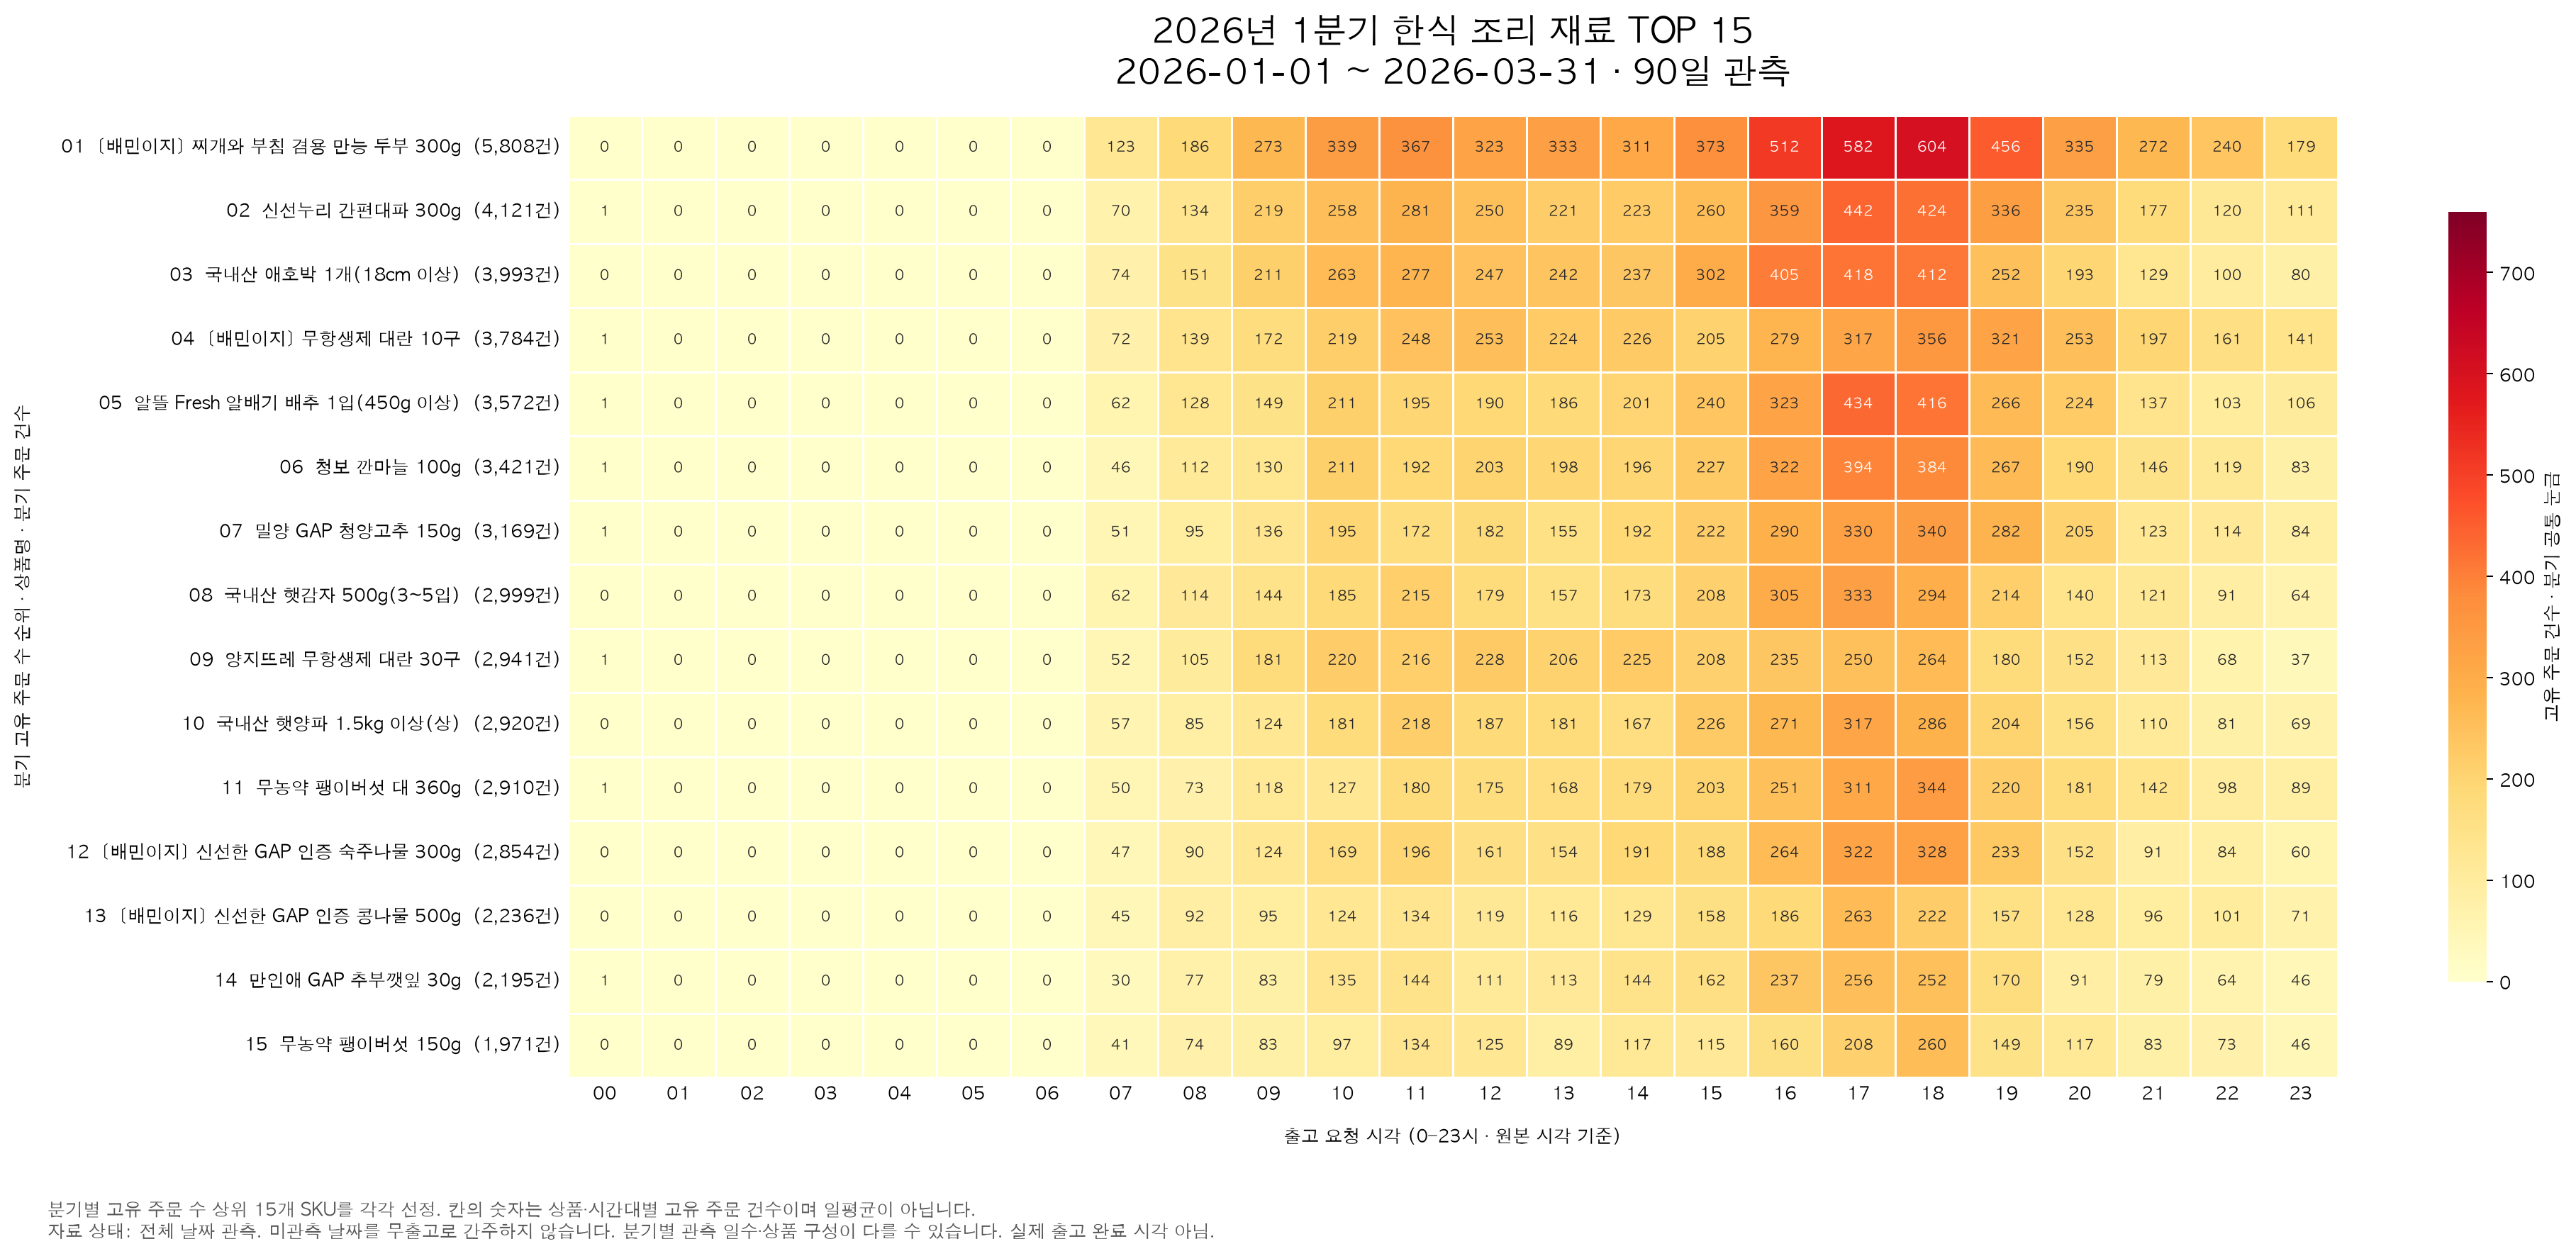

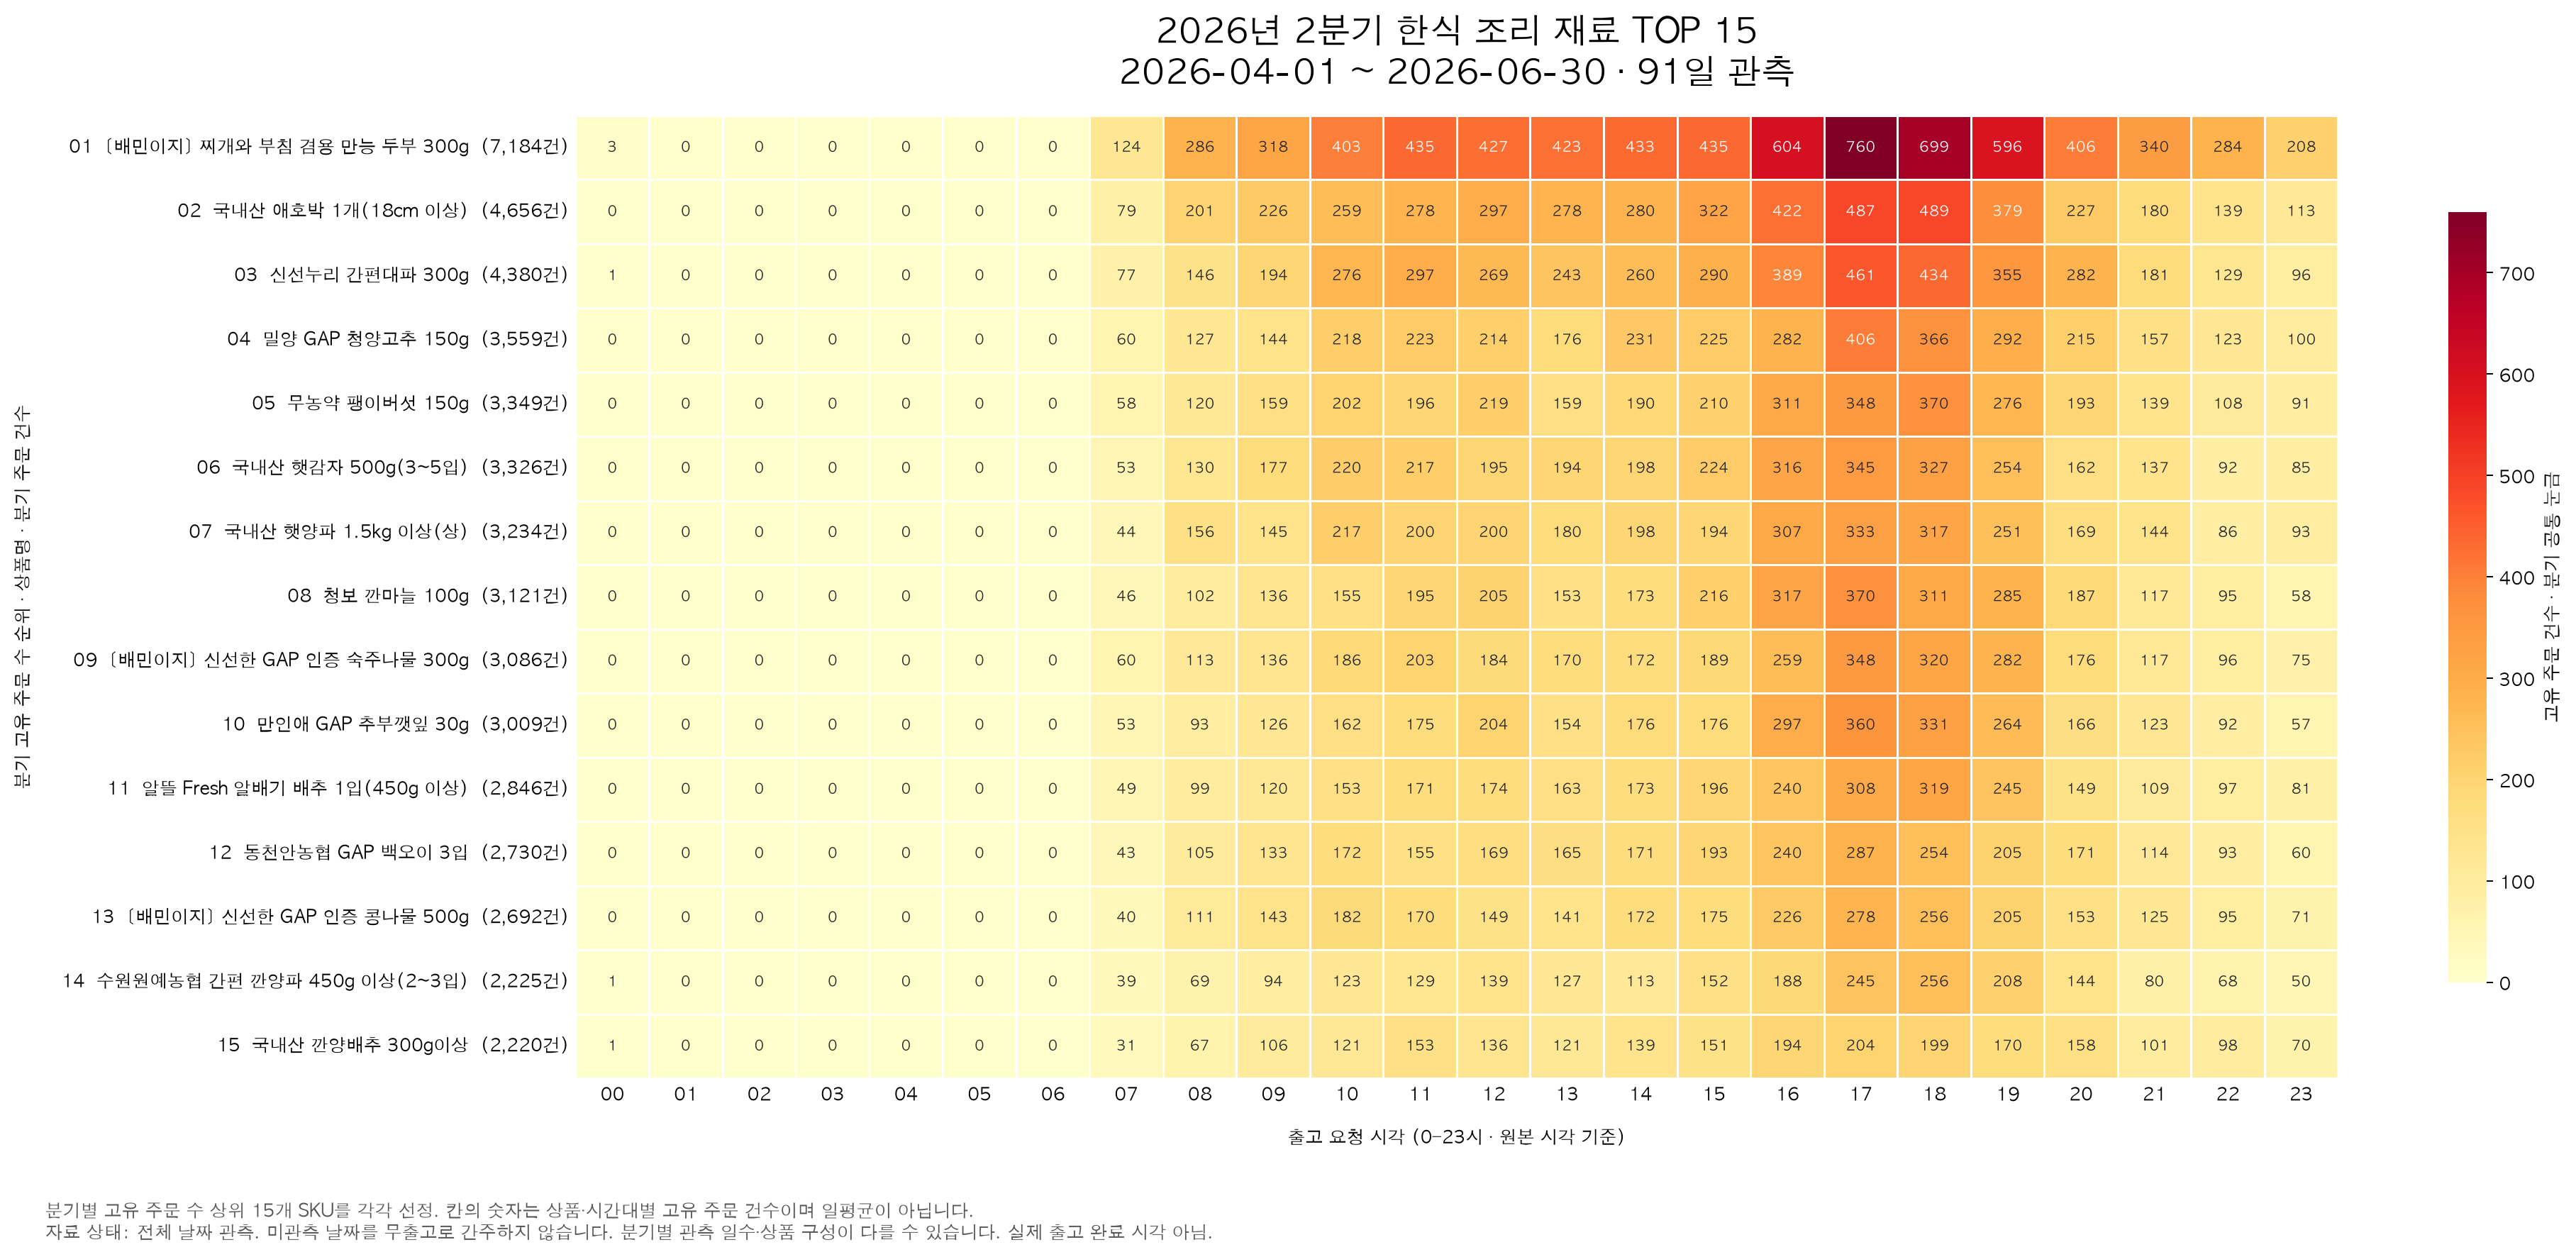

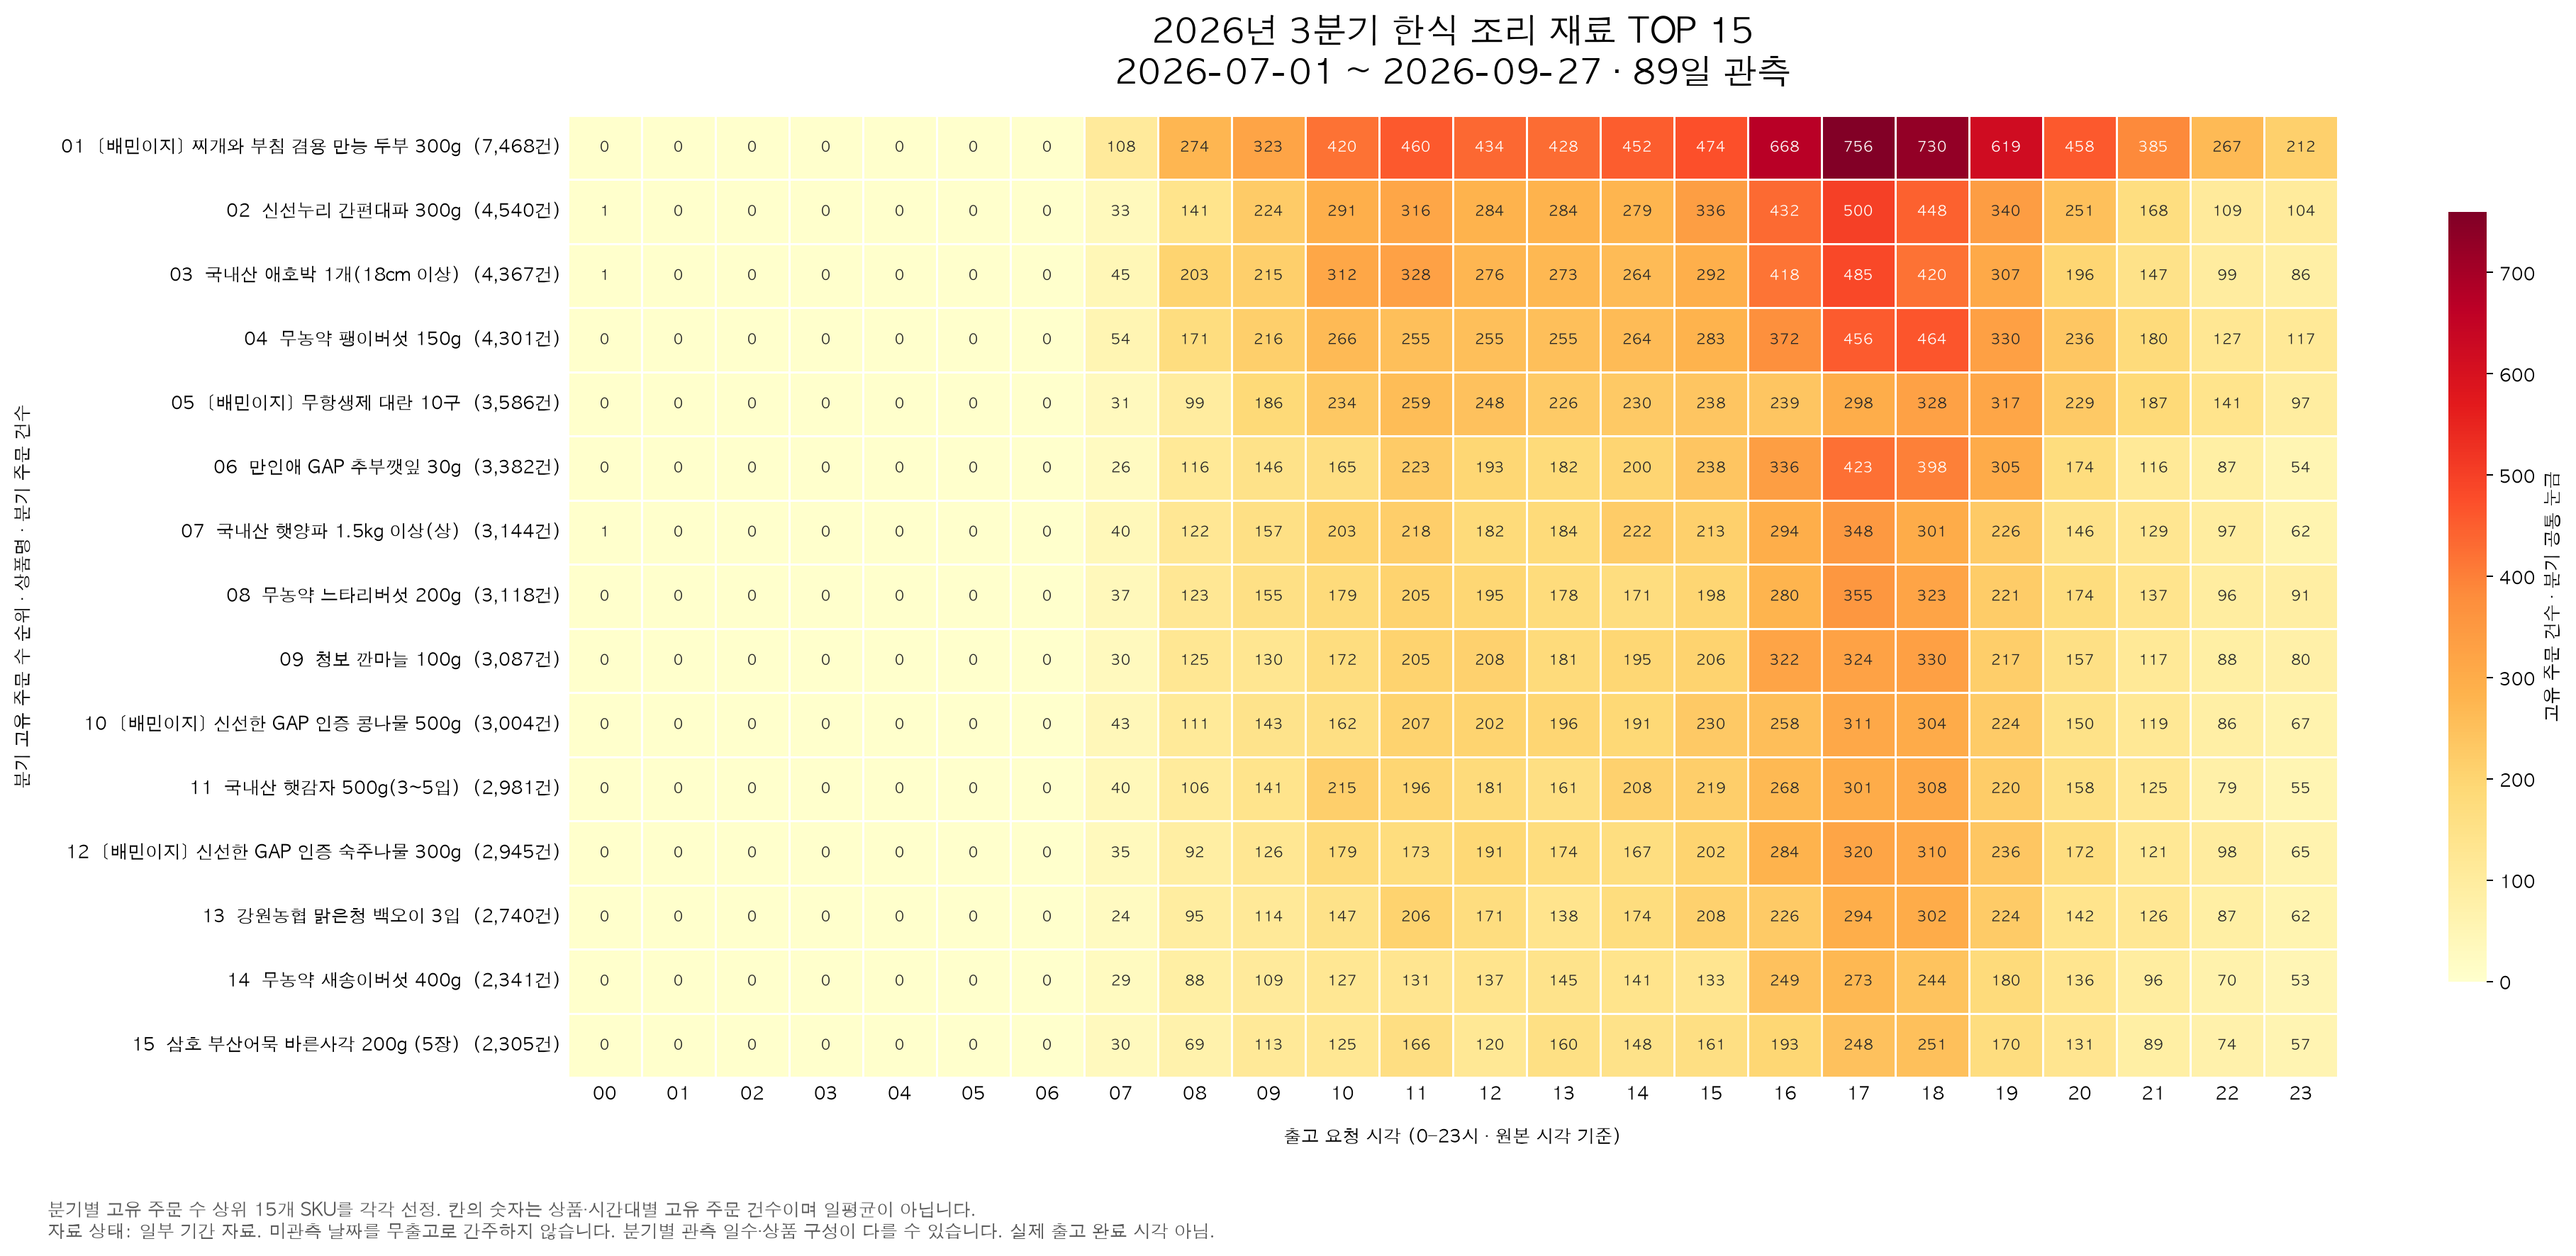

In [5]:
for filename in summary["heatmaps"]:
    display(Image(filename=str(REPORT / filename)))

## 5. 출고 행과 히트맵 일치 확인

각 분기의 TOP 15 선정 및 15 × 24 집계를 출고 행 데이터로 다시 확인합니다.

In [6]:
outbound = pd.read_parquet(DATA / "outbound_ingredients.parquet",
    columns=["requested_at", "sku_code", "hour", "order_id", "picked_quantity"])
outbound["quarter"] = outbound.requested_at.dt.quarter
assert outbound.requested_at.dt.year.eq(YEAR).all()
for quarter, group in top.groupby("quarter"):
    quarter_rows = outbound[outbound.quarter == quarter]
    expected_top = (quarter_rows.groupby("sku_code").agg(
        quarter_order_count=("order_id", "nunique"),
        quarter_picked_quantity=("picked_quantity", "sum")
    ).reset_index().sort_values(
        ["quarter_order_count", "quarter_picked_quantity", "sku_code"],
        ascending=[False, False, True]
    ).head(15))
    assert group.sku_code.tolist() == expected_top.sku_code.tolist()
    table = pd.read_csv(REPORT / f"hansik_{YEAR}_Q{quarter}_top15_hourly_heatmap.csv")
    expected_counts = (quarter_rows.groupby(["sku_code", "hour"]).order_id.nunique()
        .unstack().reindex(index=table.sku_code, columns=range(24)).fillna(0).astype(int))
    assert (expected_counts.to_numpy() == table.iloc[:, 4:].to_numpy()).all()
print("분기별 TOP 15 선정 및 모든 히트맵 칸 검증 통과")
print("Excel:", REPORT / f"hansik_ingredients_{YEAR}_quarterly.xlsx")

분기별 TOP 15 선정 및 모든 히트맵 칸 검증 통과
Excel: /Users/hoyeonjang/MyProjects/hit-stocks-analysis/reports/hansik_2026/hansik_ingredients_2026_quarterly.xlsx
